# H2: Region distribution has not changed but the age distribution has changed.
**Team 007 | An Analysis of India's Civilian and Military Honours**

**Q1:** How have civilian winners changed in region and age distribution between the first four decades (1954-1993) and the later period (1994-2021)?

- **H0:** Region and age distribution have remained the same.
- **H1:** Region changed, age unchanged.
- **H2:** Region unchanged, age changed.
- **H3:** Both changed.

**This notebook tests H2.** It reads the CSVs generated by `region_analysis.py` (`region_output/`) and `age_analysis.py` (`age_output/`), runs a significance test for region and for age, plots the evidence, and gives a verdict.

Decision rule (alpha = 0.05): region changed if the chi-square p-value < 0.05, age changed if the Mann-Whitney p-value < 0.05.

## 1. Setup

In [1]:
import os, sys, subprocess
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from scipy.stats import chi2_contingency, mannwhitneyu, ttest_ind

HYP = "H2"          # hypothesis this notebook tests
ALPHA = 0.05             # significance level

REGION_DIR, AGE_DIR, OUT_DIR = "region_output", "age_output", "hypothesis_output"
AWARDS = ["Bharat Ratna", "Padma Vibhushan", "Padma Bhushan", "Padma Shri"]
REGION_ORDER = ["North", "South", "East", "West", "Central", "North-East", "Foreign"]
slug = lambda s: s.lower().replace(" ", "_")

# The notebook reads CSVs made by region_analysis.py and age_analysis.py.
# If they are missing, generate them (needs national_awards_cleaned.csv in this folder).
if not os.path.exists(f"{REGION_DIR}/padma_shri_region_summary.csv"):
    subprocess.run([sys.executable, "region_analysis.py"], check=True)
if not os.path.exists(f"{AGE_DIR}/age_records.csv"):
    subprocess.run([sys.executable, "age_analysis.py"], check=True)
os.makedirs(OUT_DIR, exist_ok=True)

## 2. Load the generated CSVs

In [2]:
# region CSVs (one per award) -> one table
reg = pd.concat([pd.read_csv(f"{REGION_DIR}/{slug(a)}_region_summary.csv").assign(Award=a) for a in AWARDS])
st  = pd.concat([pd.read_csv(f"{REGION_DIR}/{slug(a)}_state_summary.csv").assign(Award=a) for a in AWARDS])

# age CSVs
ages     = pd.read_csv(f"{AGE_DIR}/age_records.csv")
age_bins = pd.read_csv(f"{AGE_DIR}/age_bins.csv")
age_cov  = pd.read_csv(f"{AGE_DIR}/age_coverage_by_year.csv")
age_sum  = pd.concat([pd.read_csv(f"{AGE_DIR}/{slug(a)}_age_summary.csv").assign(Award=a) for a in AWARDS]
                     + [pd.read_csv(f"{AGE_DIR}/all_civilian_age_summary.csv").assign(Award="All awards")])

P1, P2 = sorted(reg["Period"].unique())     # "1954-1993", "1994-2021"
print("Periods:", P1, "vs", P2)
print("Region records:", int(reg.Count.sum()), "| winners with an age:", len(ages))

Periods: 1954-1993 vs 1994-2021
Region records: 4875 | winners with an age: 3561


## 3. Age evidence

**Data caveat:** only winners whose birth year was added have an age. Ages exist for 1,650 of 4,875 winners, and for the later period (1994-2021) only for years up to 2009 (see the coverage plot below). So the age result applies to winners with a known age, not to every winner. Medians and the rank-based Mann-Whitney test are used because a few ages are extreme (for example 124).

In [3]:
def age_test(d):
    """Mann-Whitney U (main test) + Welch t-test (check) on age at award."""
    x = d.loc[d.Period == P1, "AgeAtAward"]; y = d.loc[d.Period == P2, "AgeAtAward"]
    u, p = mannwhitneyu(x, y, alternative="two-sided")
    return {"n_P1": len(x), "n_P2": len(y),
            "median_P1": x.median(), "median_P2": y.median(),
            "median_diff": y.median() - x.median(),
            "mean_diff": round(y.mean() - x.mean(), 2),
            "p_value": p, "p_welch": ttest_ind(x, y, equal_var=False).pvalue,
            # rank-biserial effect size; positive = later period is older
            "effect_r": round(1 - 2 * u / (len(x) * len(y)), 3)}

age_results = pd.DataFrame(
    [{"Scope": "All awards pooled", **age_test(ages)}] +
    [{"Scope": a, **age_test(ages[ages.Award == a])} for a in AWARDS])
age_results.to_csv(f"{OUT_DIR}/{HYP}_age_test.csv", index=False)
age_results

,Scope,n_P1,n_P2,median_P1,median_P2,median_diff,mean_diff,p_value,p_welch,effect_r
0,All awards pooled,1405,2156,60.0,69.0,9.0,8.39,2.100745e-75,3.534085e-66,0.364
1,Bharat Ratna,22,19,74.5,87.0,12.5,10.03,3.384991e-02,8.802397e-02,0.390
2,Padma Vibhushan,109,152,66.0,78.0,12.0,9.55,1.224810e-10,1.686976e-09,0.467
3,Padma Bhushan,502,451,62.0,73.0,11.0,9.19,1.769852e-31,3.947482e-28,0.437
4,Padma Shri,772,1534,55.0,66.0,11.0,9.88,2.346985e-61,3.257629e-57,0.421


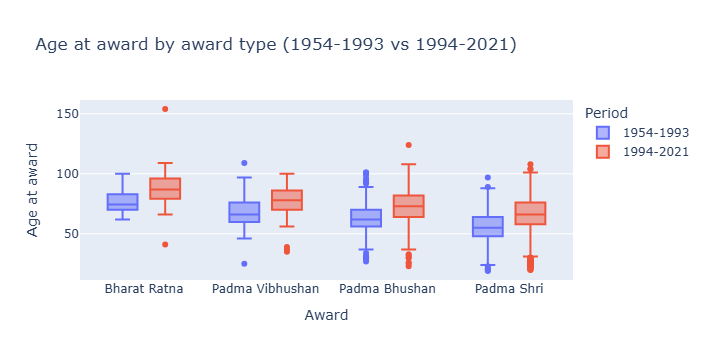

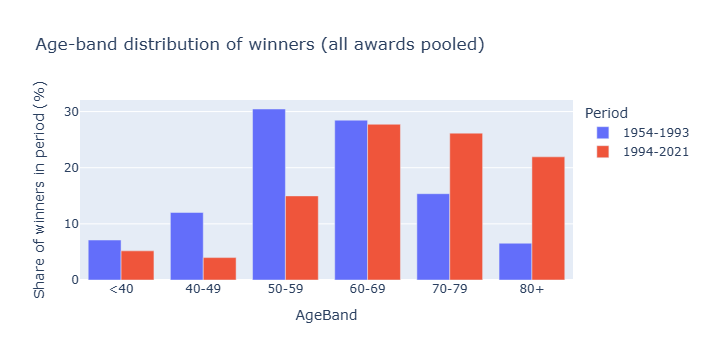

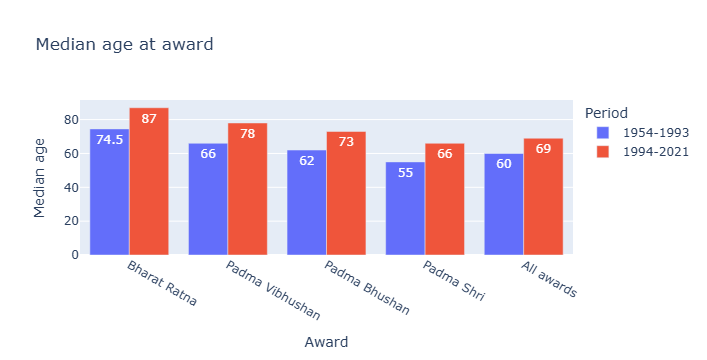

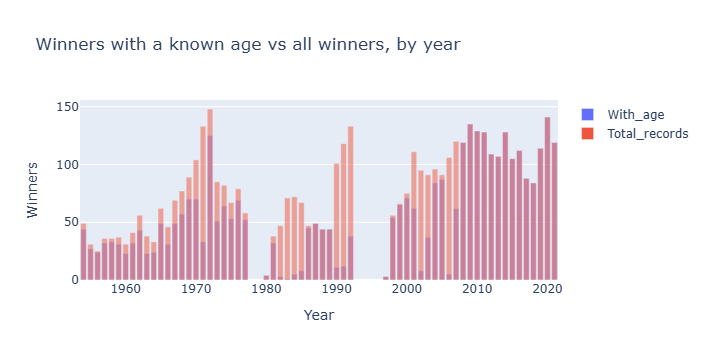

In [4]:
# 1) Age distribution per award and period
fig = px.box(ages, x="Award", y="AgeAtAward", color="Period", points="outliers",
             category_orders={"Award": AWARDS},
             title=f"Age at award by award type ({P1} vs {P2})", labels={"AgeAtAward": "Age at award"})
fig.write_html(f"{OUT_DIR}/{HYP}_age_boxplot.html"); fig.show()

# 2) Share of winners per age band (all awards pooled)
b = age_bins[age_bins.Award == "All awards"]
fig = px.bar(b, x="AgeBand", y="Share_%", color="Period", barmode="group",
             category_orders={"AgeBand": ["<40", "40-49", "50-59", "60-69", "70-79", "80+"]},
             title="Age-band distribution of winners (all awards pooled)",
             labels={"Share_%": "Share of winners in period (%)"})
fig.write_html(f"{OUT_DIR}/{HYP}_age_bands.html"); fig.show()

# 3) Median age (from the summary CSVs)
fig = px.bar(age_sum, x="Award", y="median", color="Period", barmode="group", text="median",
             category_orders={"Award": AWARDS + ["All awards"]},
             title="Median age at award", labels={"median": "Median age"})
fig.write_html(f"{OUT_DIR}/{HYP}_median_age.html"); fig.show()

# 4) Data quality: how many winners have an age, by year
fig = px.bar(age_cov, x="Year", y=["With_age", "Total_records"], barmode="overlay",
             title="Winners with a known age vs all winners, by year",
             labels={"value": "Winners", "variable": ""})
fig.write_html(f"{OUT_DIR}/{HYP}_age_coverage.html"); fig.show()

## 4. Region evidence

In [5]:
def region_test(df):
    """Chi-square test on the Period x Region count table."""
    tab = df.pivot_table(index="Period", columns="Region", values="Count", aggfunc="sum").fillna(0)
    tab = tab.loc[:, tab.sum() > 0]
    chi2, p, dof, exp = chi2_contingency(tab)
    n = tab.values.sum()
    return {"n": int(n), "chi2": round(chi2, 2), "dof": dof, "p_value": p,
            "cramers_v": round(np.sqrt(chi2 / (n * (min(tab.shape) - 1))), 3),
            "reliable": bool((exp < 5).mean() <= 0.2)}

region_results = pd.DataFrame(
    [{"Scope": "All civilian awards", **region_test(reg)}] +
    [{"Scope": a, **region_test(reg[reg.Award == a])} for a in AWARDS])
region_results.to_csv(f"{OUT_DIR}/{HYP}_region_test.csv", index=False)
region_results

,Scope,n,chi2,dof,p_value,cramers_v,reliable
0,All civilian awards,4875,135.61,6,8.438835e-27,0.167,True
1,Bharat Ratna,48,5.75,5,3.315352e-01,0.346,False
2,Padma Vibhushan,321,13.56,6,3.494487e-02,0.206,False
3,Padma Bhushan,1281,59.83,6,4.862302e-11,0.216,True
4,Padma Shri,3225,89.65,6,3.589913e-17,0.167,True


**How to read it:** `p_value < 0.05` means the region mix differs between the two periods. `cramers_v` is the effect size (about 0.1 small, 0.3 medium, 0.5 large). `reliable = False` means many expected counts are below 5, so ignore that row (the "All civilian awards" row is the headline).

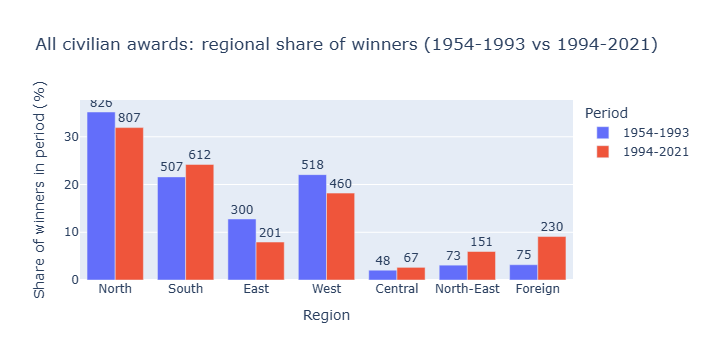

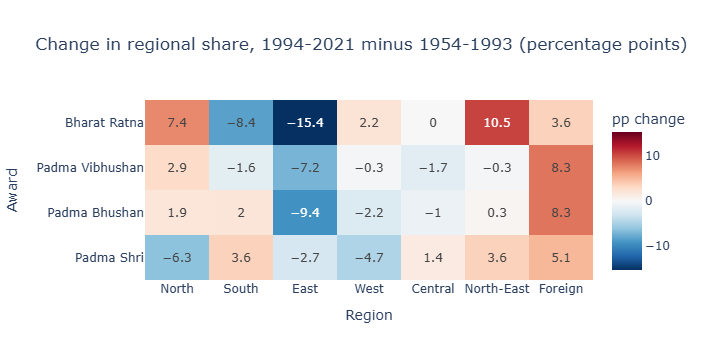

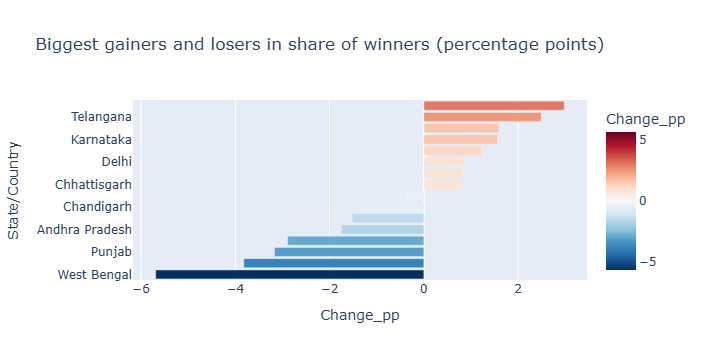

In [6]:
# 1) Pooled regional share, both periods
pool = reg.groupby(["Period", "Region"], as_index=False)["Count"].sum()
pool["Share_%"] = (pool["Count"] / pool.groupby("Period")["Count"].transform("sum") * 100).round(2)
fig = px.bar(pool, x="Region", y="Share_%", color="Period", barmode="group", text="Count",
             category_orders={"Region": REGION_ORDER},
             title=f"All civilian awards: regional share of winners ({P1} vs {P2})",
             labels={"Share_%": "Share of winners in period (%)"})
fig.update_traces(textposition="outside")
fig.write_html(f"{OUT_DIR}/{HYP}_region_share.html"); fig.show()

# 2) Change in share (percentage points) per award
a = reg.pivot_table(index=["Award", "Region"], columns="Period", values="Share_%")
a["Change_pp"] = (a[P2] - a[P1]).round(1)
heat = a["Change_pp"].unstack("Region").reindex(index=AWARDS, columns=REGION_ORDER)
fig = px.imshow(heat, text_auto=True, aspect="auto", color_continuous_scale="RdBu_r",
                color_continuous_midpoint=0,
                title=f"Change in regional share, {P2} minus {P1} (percentage points)",
                labels=dict(color="pp change"))
fig.write_html(f"{OUT_DIR}/{HYP}_region_change_heatmap.html"); fig.show()

# 3) Which states gained / lost most share (from the state CSVs)
s = st.groupby(["Period", "State/Country"], as_index=False)["Count"].sum()
s["Share_%"] = s["Count"] / s.groupby("Period")["Count"].transform("sum") * 100
sp = s.pivot(index="State/Country", columns="Period", values="Share_%").fillna(0)
sp["Change_pp"] = (sp[P2] - sp[P1]).round(2)
movers = pd.concat([sp.nlargest(8, "Change_pp"), sp.nsmallest(8, "Change_pp")]).reset_index()
fig = px.bar(movers.sort_values("Change_pp"), x="Change_pp", y="State/Country", orientation="h",
             color="Change_pp", color_continuous_scale="RdBu_r", color_continuous_midpoint=0,
             title="Biggest gainers and losers in share of winners (percentage points)")
fig.write_html(f"{OUT_DIR}/{HYP}_state_movers.html"); fig.show()

## 5. Verdict for H2

Region test:  p = 8.44e-27 -> changed
Age test:     p = 2.1e-75 -> changed

H2 claims: Region distribution has NOT changed, age distribution has CHANGED
Data best supports: H3  (BOTH region and age distributions have changed)

>>> H2 is NOT SUPPORTED by the data (alpha = 0.05).


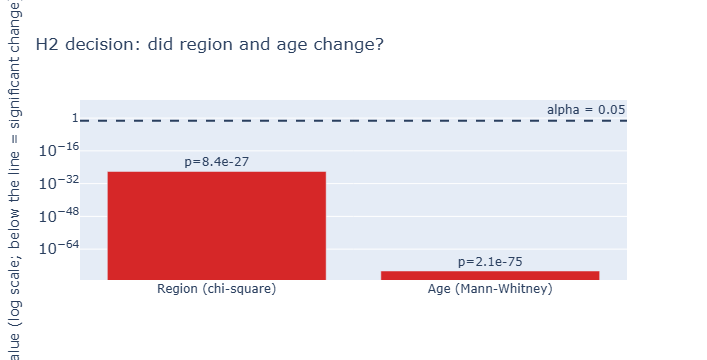

In [7]:
region_p = region_results.loc[0, "p_value"]
age_p    = age_results.loc[0, "p_value"]
region_changed = region_p < ALPHA
age_changed    = age_p < ALPHA

best_fit = {(False, False): "H0", (True, False): "H1",
            (False, True): "H2",  (True, True): "H3"}[(region_changed, age_changed)]
claims = {"H1": "Region distribution has CHANGED, age distribution has NOT",
          "H2": "Region distribution has NOT changed, age distribution has CHANGED",
          "H3": "BOTH region and age distributions have changed",
          "H0": "NEITHER region nor age distribution has changed"}

print(f"Region test:  p = {region_p:.3g} -> {'changed' if region_changed else 'no significant change'}")
print(f"Age test:     p = {age_p:.3g} -> {'changed' if age_changed else 'no significant change'}")
print(f"\n{HYP} claims: {claims[HYP]}")
print(f"Data best supports: {best_fit}  ({claims[best_fit]})")
print(f"\n>>> {HYP} is {'SUPPORTED' if best_fit == HYP else 'NOT SUPPORTED'} by the data (alpha = {ALPHA}).")

# decision plot: p-values against the alpha line
fig = go.Figure(go.Bar(x=["Region (chi-square)", "Age (Mann-Whitney)"], y=[region_p, age_p],
                       marker_color=["#d62728" if p < ALPHA else "#2ca02c" for p in (region_p, age_p)],
                       text=[f"p={region_p:.2g}", f"p={age_p:.2g}"], textposition="outside"))
fig.add_hline(y=ALPHA, line_dash="dash", annotation_text=f"alpha = {ALPHA}")
fig.update_yaxes(type="log", title="p-value (log scale; below the line = significant change)")
fig.update_layout(title=f"{HYP} decision: did region and age change?")
fig.write_html(f"{OUT_DIR}/{HYP}_decision.html"); fig.show()